In [2]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Annotated
from langchain_core.messages import BaseMessage,HumanMessage
from langchain_groq import ChatGroq
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from dotenv import load_dotenv
load_dotenv()
from langgraph.prebuilt import ToolNode,tools_condition
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_core.tools import tool
import requests
import random

C:\Users\Ali Ansari\AppData\Local\Temp\ipykernel_11596\4202309632.py:10: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import DuckDuckGoSearchRun


In [3]:
llm=ChatGroq(model="openai/gpt-oss-20b",temperature=0)

In [4]:
#tools
search_tool=DuckDuckGoSearchRun()

@tool
def calculator(first_num:float,second_num:float,operation:str)->dict:
    """
    perform a basic arithemetic operation on two numbers, supported operations : add,sub,mul,div 
    """
    try:
        if operation=="add":
            result=first_num+second_num
        elif operation=="sub":
            result=first_num-second_num
        elif operation=="mul":
            result=first_num*second_num
        elif operation=="div":
            if second_num==0:
                return {"error":"division by zero is not allowed"}
            result=first_num/second_num
        else:
            return {"error":f"Unsupported operation '{operation}'"}

        return {"first_num":first_num,"second_num":second_num,"operation":operation,"result":result}

    except Exception as e:
        return{"error":str(e)}


@tool
def get_stock_price(symbol:str)->dict:
    """
    fetch latest stock price for a given symbol (eg:'AAPL','TSLA') using alpha vantage with api key in the url
    """
    url="https://www.alphavantage.co/support/#api-key=V5RUYL0Q9G9EZBC4"
    r=response.get(url)
    return r.json()

In [5]:
#make tool list
tools=[get_stock_price,search_tool,calculator]
#make the llm tool aware
llm_with_tools=llm.bind_tools(tools)

In [6]:
#state
class ChatState(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]

In [7]:
#graph nodes
def chat_nodes(state:ChatState):
    """
    llm node that may answer and request a tool call
    """
    messages=state['messages']
    response=llm_with_tools.invoke(messages)
    return {'messages':[response]}

tool_node=ToolNode(tools)


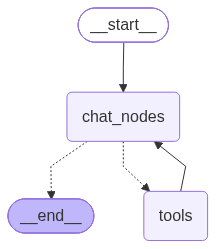

In [8]:
#graph structure
graph=StateGraph(ChatState)
graph.add_node("chat_nodes",chat_nodes)
graph.add_node("tools",tool_node)

graph.add_edge(START,"chat_nodes")
graph.add_conditional_edges("chat_nodes",tools_condition)
graph.add_edge("tools","chat_nodes")
chatbot=graph.compile()
chatbot



In [ ]:
out=chatbot.invoke({"messages":[HumanMessage(content="what is stock price of apple?")]})
print(out["messages"][-1].content)

2 × 3 = 6.
